<a href="https://colab.research.google.com/github/muthu2106/Deep-Learning-Assignment/blob/main/CAP_Stone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q seaborn scikit-learn

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import kagglehub
import os

dataset_path = kagglehub.dataset_download(
    "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
)

print("Dataset downloaded to:", dataset_path)

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level <= 2:
        print(root)
        print("Folders:", dirs[:8])
        print("Files:", files[:8])

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Dataset downloaded to: /kaggle/input/gtsrb-german-traffic-sign
/kaggle/input/gtsrb-german-traffic-sign
Folders: ['Meta', 'meta', 'Test', 'test', 'Train', 'train']
Files: ['Meta.csv', 'Train.csv', 'Test.csv']
/kaggle/input/gtsrb-german-traffic-sign/Meta
Folders: []
Files: ['37.png', '35.png', '11.png', '31.png', '4.png', '40.png', '33.png', '9.png']
/kaggle/input/gtsrb-german-traffic-sign/meta
Folders: []
Files: ['37.png', '35.png', '11.png', '31.png', '4.png', '40.png', '33.png', '9.png']
/kaggle/input/gtsrb-german-traffic-sign/Test
Folders: []
Files: ['01301.png', '02578.png', '06781.png', '11396.png', '00929.png', '04915.png', '07470.png', '08216.png']
/kaggle/input/gtsrb-german-traffic-sign/test
Folders: []
Files: ['01301.png', '02578.png', '06781.png', '11396.png', '00929.png', '04915.png', '07470.png', '08216.png']
/kaggle/input/gtsrb-german-traffic-sign/Train
Folders: ['7', '17', '19', '22', '2', '35'

In [ ]:
import os

train_csv_files = []
test_csv_files = []
class_folder_candidates = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.lower() == "train.csv":
            train_csv_files.append(os.path.join(root, file))

        elif file.lower() == "test.csv":
            test_csv_files.append(os.path.join(root, file))

    numeric_dirs = [
        d for d in dirs
        if d.isdigit() and 0 <= int(d) <= 42
    ]

    if len(numeric_dirs) >= 40:
        class_folder_candidates.append(root)

print("Train CSV files:", train_csv_files)
print("Test CSV files:", test_csv_files)
print("Class folder candidates:", class_folder_candidates)

Train CSV files: ['/kaggle/input/gtsrb-german-traffic-sign/Train.csv']
Test CSV files: ['/kaggle/input/gtsrb-german-traffic-sign/Test.csv']
Class folder candidates: ['/kaggle/input/gtsrb-german-traffic-sign/Train', '/kaggle/input/gtsrb-german-traffic-sign/train']


In [ ]:
import os
import pandas as pd

DATASET_PATH = "/kaggle/input/gtsrb-german-traffic-sign"

train_df = pd.read_csv(os.path.join(DATASET_PATH, "Train.csv"))
test_df = pd.read_csv(os.path.join(DATASET_PATH, "Test.csv"))

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nTraining samples:")
display(train_df.head())

print("\nTesting samples:")
display(test_df.head())

Training shape: (39209, 8)
Testing shape: (12630, 8)

Training columns:
['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']

Training samples:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png



Testing samples:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,53,54,6,5,48,49,16,Test/00000.png
1,42,45,5,5,36,40,1,Test/00001.png
2,48,52,6,6,43,47,38,Test/00002.png
3,27,29,5,5,22,24,33,Test/00003.png
4,60,57,5,5,55,52,11,Test/00004.png


In [ ]:
from pathlib import Path

def find_image_path(relative_path, split):
    relative_path = str(relative_path).replace("\\", "/").lstrip("/")

    candidates = [
        os.path.join(DATASET_PATH, relative_path),
        os.path.join(DATASET_PATH, split, relative_path),
        os.path.join(DATASET_PATH, split.lower(), relative_path),
    ]

    for path in candidates:
        if os.path.isfile(path):
            return path

    filename = os.path.basename(relative_path)

    matches = glob.glob(
        os.path.join(DATASET_PATH, split, "**", filename),
        recursive=True
    )

    if not matches:
        matches = glob.glob(
            os.path.join(DATASET_PATH, split.lower(), "**", filename),
            recursive=True
        )

    return matches[0] if matches else None


def identify_column(df, options):
    for col in options:
        if col in df.columns:
            return col
    return None


path_col = identify_column(
    train_df,
    ["Path", "path", "Filename", "filename", "Filepath", "filepath"]
)

label_col = identify_column(
    train_df,
    ["ClassId", "ClassID", "class_id", "Label", "label"]
)

print("Image column:", path_col)
print("Label column:", label_col)

if path_col is None or label_col is None:
    raise ValueError(
        "Could not identify image path and class label columns. "
        "Check Cell 5 output."
    )

train_df["resolved_path"] = [
    find_image_path(path, "Train")
    for path in train_df[path_col]
]

train_df = train_df.dropna(subset=["resolved_path"]).copy()
train_df[label_col] = train_df[label_col].astype(int)

print("Usable training images:", len(train_df))
print("Number of classes:", train_df[label_col].nunique())
print("Class IDs:", sorted(train_df[label_col].unique()))

if train_df.empty:
    raise ValueError("No training images were found.")

Image column: Path
Label column: ClassId
Usable training images: 39209
Number of classes: 43
Class IDs: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42)]


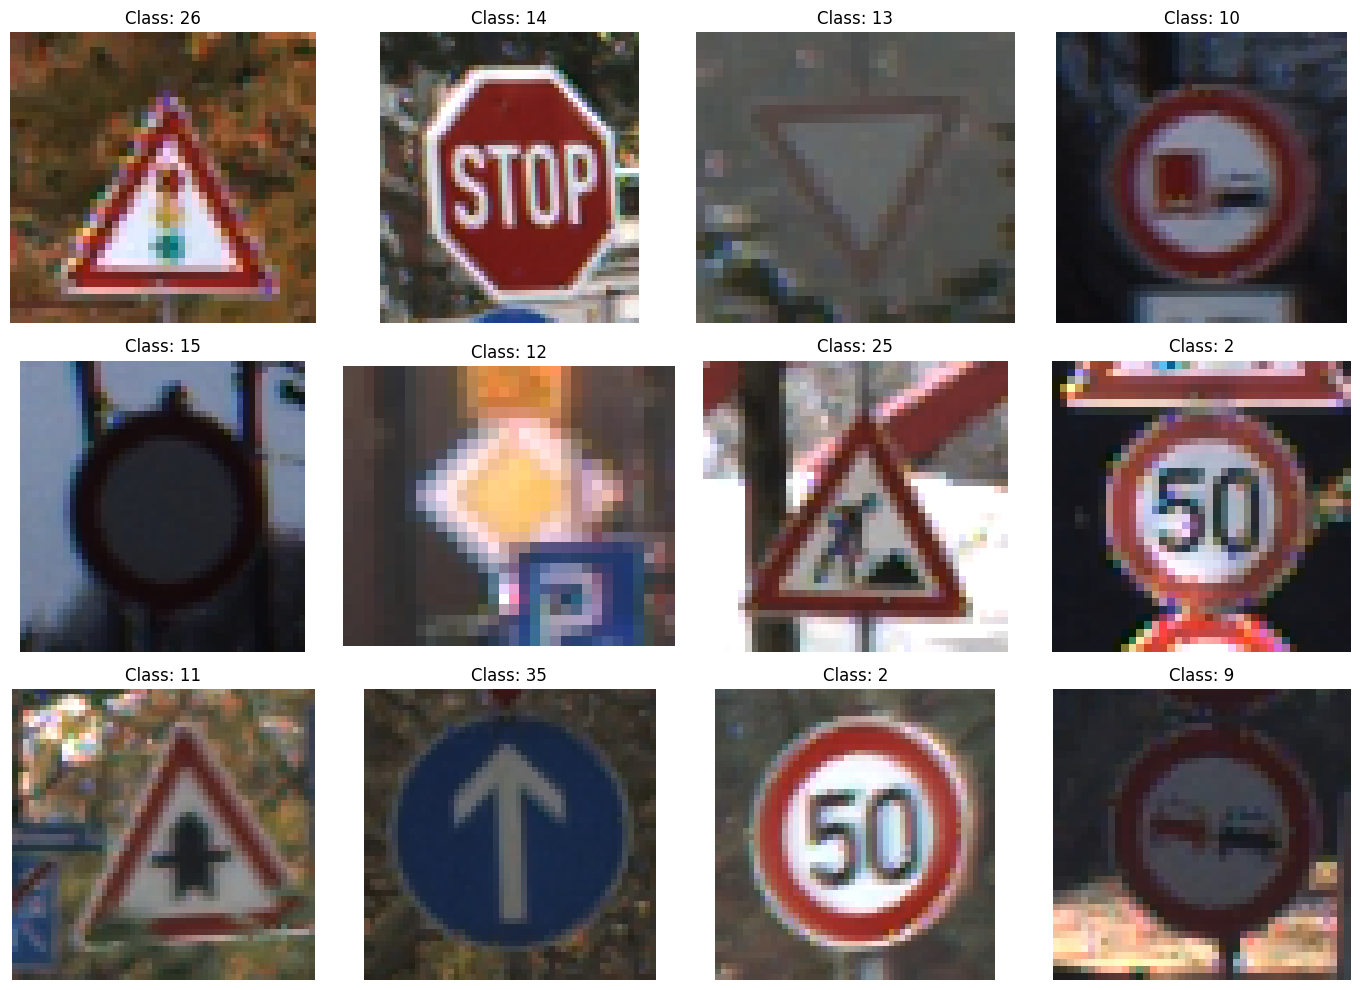

In [ ]:
from PIL import Image

sample_df = train_df.sample(
    min(12, len(train_df)),
    random_state=42
)

plt.figure(figsize=(14, 10))

for i, (_, row) in enumerate(sample_df.iterrows()):
    image = Image.open(row["resolved_path"]).convert("RGB")

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(f"Class: {row[label_col]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

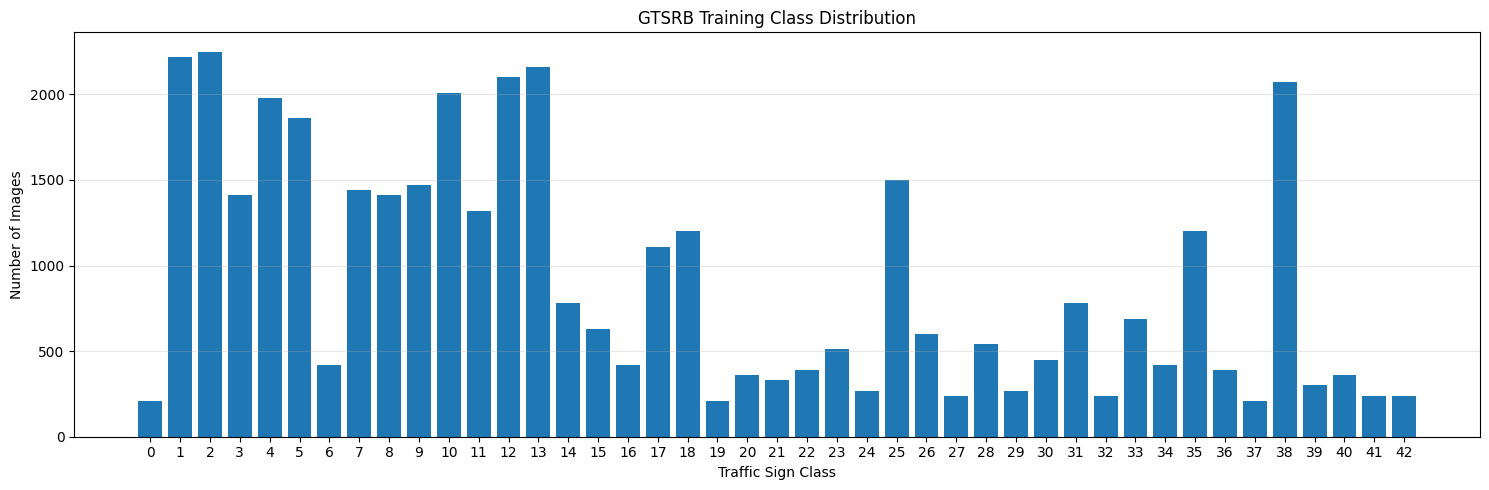

In [ ]:
class_counts = train_df[label_col].value_counts().sort_index()

plt.figure(figsize=(15, 5))
plt.bar(class_counts.index, class_counts.values)
plt.xlabel("Traffic Sign Class")
plt.ylabel("Number of Images")
plt.title("GTSRB Training Class Distribution")
plt.xticks(range(43))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:

NUM_CLASSES = 43

train_paths, val_paths, train_labels, val_labels = train_test_split(
    train_df["resolved_path"].to_numpy(),
    train_df[label_col].to_numpy(),
    test_size=0.20,
    random_state=42,
    stratify=train_df[label_col].to_numpy()
)

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Number of classes:", NUM_CLASSES)

Training images: 31367
Validation images: 7842
Number of classes: 43


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 64
NUM_CLASSES = 43

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)

Image size: (224, 224)
Batch size: 64
Number of classes: 43


abve is cell 10.1
below is cell 10.2(orginal 10)

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)
    return image, tf.cast(label, tf.int32)

train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

train_ds = (
    train_ds
    .shuffle(len(train_paths), seed=42)
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_ds
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Training and validation datasets created successfully.")

Training and validation datasets created successfully.


In [ ]:
augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.04),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.10)
])

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 43)             │        55,083 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,313,067 (8.82 MB)

 Trainable params: 55,083 (215.17 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
callbacks = [
    ModelCheckpoint(
        "/kaggle/working/GTSRB_best_model.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        patience=3,
        restore_best_weights=True,
        mode="max",
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks
)

Epoch 1/8
491/491 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step - accuracy: 0.2505 - loss: 2.8485
Epoch 1: val_accuracy improved from None to 0.48763, saving model to /kaggle/working/GTSRB_best_model.keras

Epoch 1: finished saving model to /kaggle/working/GTSRB_best_model.keras
491/491 ━━━━━━━━━━━━━━━━━━━━ 118s 211ms/step - accuracy: 0.3368 - loss: 2.4429 - val_accuracy: 0.4876 - val_loss: 1.8030 - learning_rate: 0.0010
Epoch 2/8
490/491 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - accuracy: 0.4486 - loss: 2.0188
Epoch 2: val_accuracy improved from 0.48763 to 0.51313, saving model to /kaggle/working/GTSRB_best_model.keras

Epoch 2: finished saving model to /kaggle/working/GTSRB_best_model.keras
491/491 ━━━━━━━━━━━━━━━━━━━━ 67s 136ms/step - accuracy: 0.4615 - loss: 1.9715 - val_accuracy: 0.5131 - val_loss: 1.7133 - learning_rate: 0.0010
Epoch 3/8
490/491 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.4930 - loss: 1.8374
Epoch 3: val_accuracy improved from 0.51313 to 0.52448, saving model to /kaggle/wor

In [ ]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks
)

Epoch 1/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.5440 - loss: 1.6347
Epoch 1: val_accuracy improved from 0.53736 to 0.56044, saving model to /kaggle/working/GTSRB_best_model.keras

Epoch 1: finished saving model to /kaggle/working/GTSRB_best_model.keras
491/491 ━━━━━━━━━━━━━━━━━━━━ 82s 153ms/step - accuracy: 0.5500 - loss: 1.6049 - val_accuracy: 0.5604 - val_loss: 1.7485 - learning_rate: 1.0000e-05
Epoch 2/5
490/491 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.5674 - loss: 1.5551
Epoch 2: val_accuracy did not improve from 0.56044

Epoch 2: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.
491/491 ━━━━━━━━━━━━━━━━━━━━ 73s 148ms/step - accuracy: 0.5721 - loss: 1.5341 - val_accuracy: 0.5448 - val_loss: 1.9019 - learning_rate: 1.0000e-05
Epoch 3/5
490/491 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.5868 - loss: 1.4768
Epoch 3: val_accuracy improved from 0.56044 to 0.56376, saving model to /kaggle/working/GTSRB_best_model.keras

Epoch 3: finished

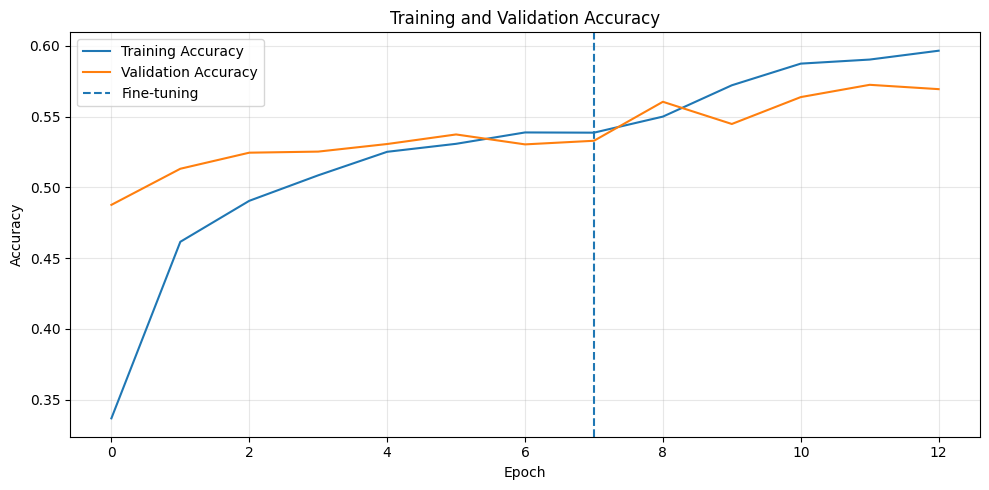

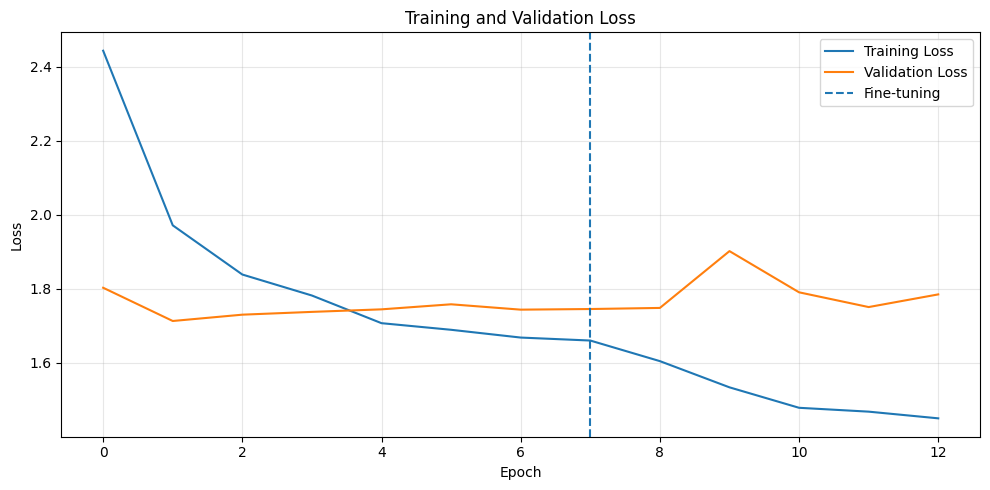

In [ ]:
train_acc = history1.history["accuracy"] + history2.history["accuracy"]
val_acc = history1.history["val_accuracy"] + history2.history["val_accuracy"]
train_loss = history1.history["loss"] + history2.history["loss"]
val_loss = history1.history["val_loss"] + history2.history["val_loss"]

plt.figure(figsize=(10, 5))
plt.plot(train_acc, label="Training Accuracy")
plt.plot(val_acc, label="Validation Accuracy")
plt.axvline(len(history1.history["accuracy"]) - 1, linestyle="--", label="Fine-tuning")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/kaggle/working/accuracy_graph.png", dpi=300)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(train_loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.axvline(len(history1.history["loss"]) - 1, linestyle="--", label="Fine-tuning")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/kaggle/working/loss_graph.png", dpi=300)
plt.show()

In [ ]:
val_loss_value, val_accuracy_value = model.evaluate(val_ds, verbose=1)

print(f"Validation accuracy: {val_accuracy_value * 100:.2f}%")
print(f"Validation loss: {val_loss_value:.4f}")

y_true = np.concatenate([
    labels.numpy()
    for _, labels in val_ds
])

y_prob = model.predict(val_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    digits=4,
    zero_division=0
)

print(report)

with open("/kaggle/working/classification_report.txt", "w") as f:
    f.write(report)

123/123 ━━━━━━━━━━━━━━━━━━━━ 18s 148ms/step - accuracy: 0.5724 - loss: 1.7509
Validation accuracy: 57.24%
Validation loss: 1.7509
123/123 ━━━━━━━━━━━━━━━━━━━━ 15s 114ms/step
              precision    recall  f1-score   support

           0     0.3016    0.4524    0.3619        42
           1     0.4128    0.7725    0.5380       444
           2     0.2678    0.7511    0.3949       450
           3     0.6744    0.2057    0.3152       282
           4     0.4711    0.6389    0.5423       396
           5     0.5528    0.1828    0.2747       372
           6     0.0000    0.0000    0.0000        84
           7     0.6277    0.7083    0.6656       288
           8     0.0909    0.0035    0.0068       282
           9     0.6312    0.8265    0.7158       294
          10     0.7843    0.1990    0.3175       402
          11     0.8289    0.2386    0.3706       264
          12     0.9923    0.9214    0.9556       420
          13     0.9907    0.9907    0.9907       432
          14   

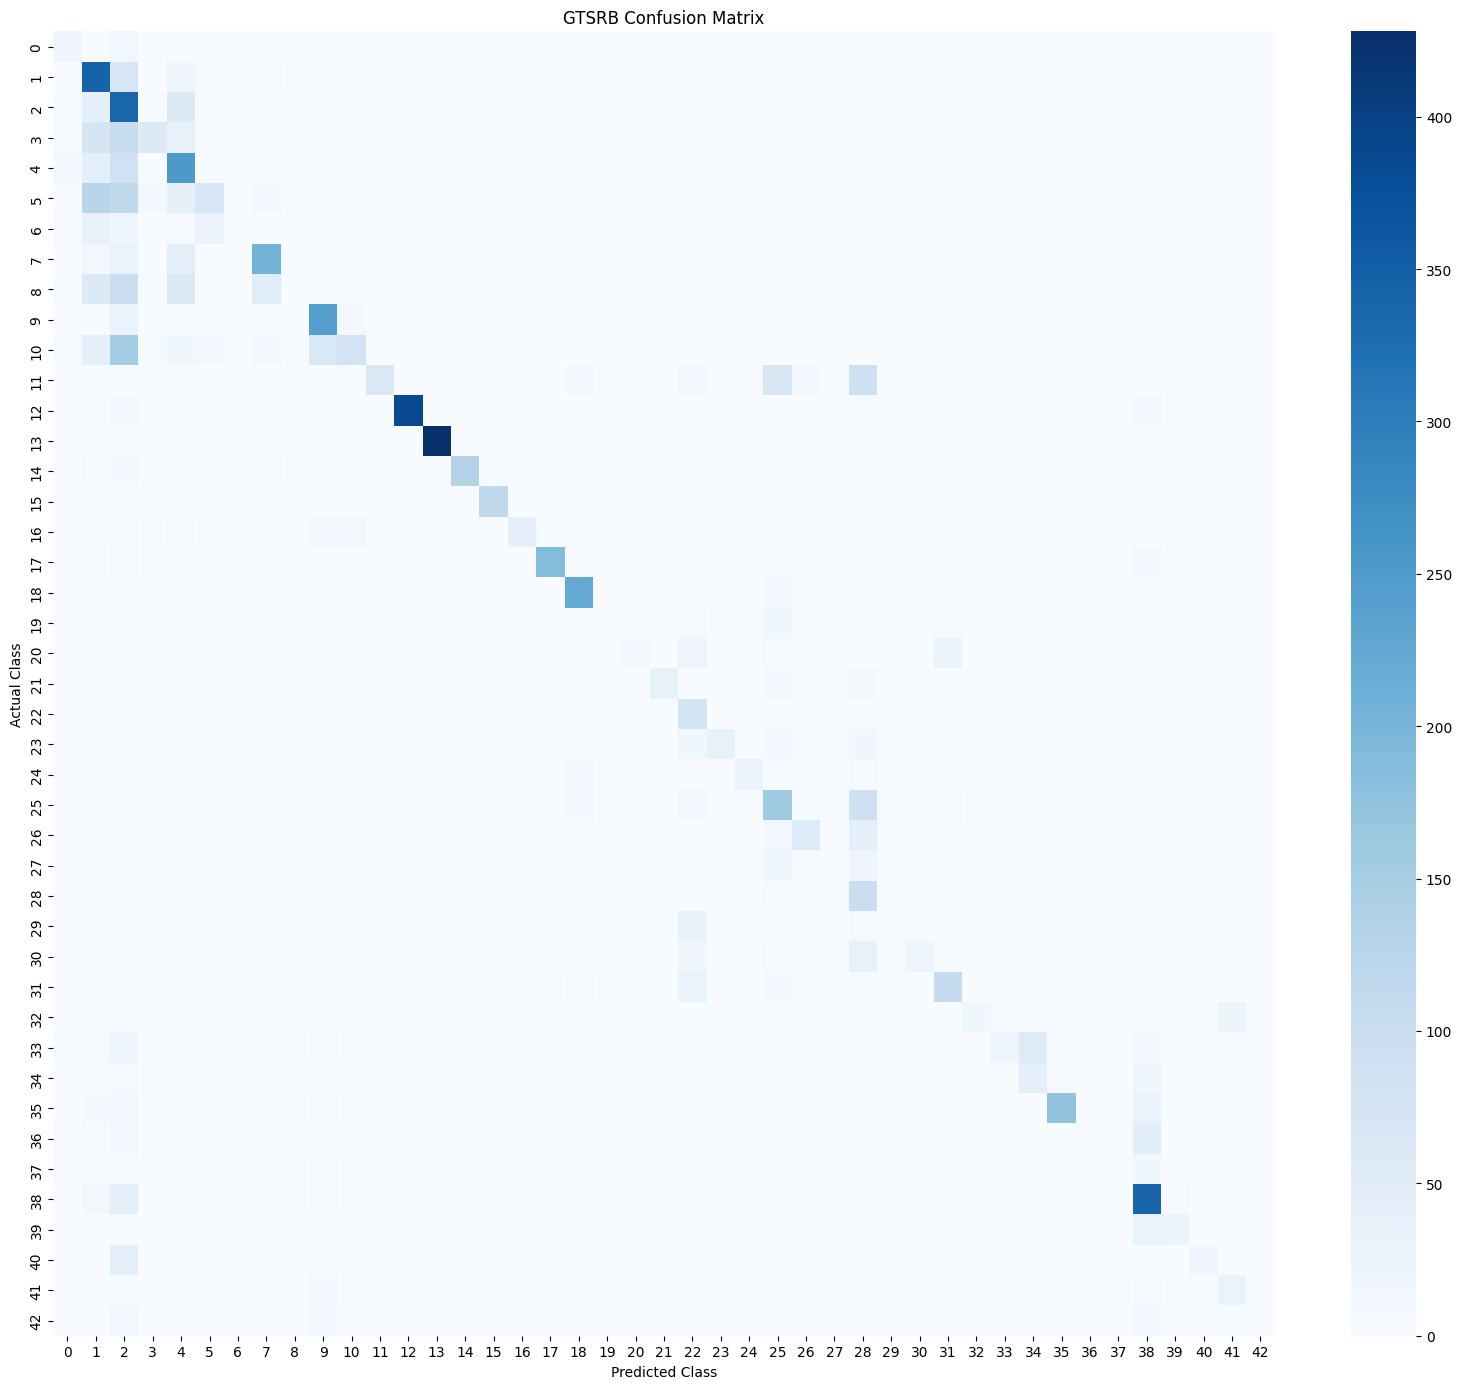

In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

plt.figure(figsize=(16, 14))
sns.heatmap(cm, cmap="Blues", annot=False)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("GTSRB Confusion Matrix")
plt.tight_layout()
plt.savefig("/kaggle/working/confusion_matrix.png", dpi=300)
plt.show()

In [ ]:
model.save("/kaggle/working/GTSRB_MobileNetV2_Final.keras")

results = pd.DataFrame({
    "Metric": [
        "Dataset",
        "Number of classes",
        "Training images",
        "Validation images",
        "Image size",
        "Model",
        "Validation accuracy",
        "Validation loss"
    ],
    "Value": [
        "GTSRB",
        NUM_CLASSES,
        len(train_paths),
        len(val_paths),
        "224 x 224 x 3",
        "MobileNetV2 Transfer Learning",
        f"{val_accuracy_value * 100:.2f}%",
        f"{val_loss_value:.4f}"
    ]
})

results.to_csv("/kaggle/working/GTSRB_results.csv", index=False)

display(results)

print("Saved model and evaluation outputs to /kaggle/working/")

,Metric,Value
0,Dataset,GTSRB
1,Number of classes,43
2,Training images,31367
3,Validation images,7842
4,Image size,224 x 224 x 3
5,Model,MobileNetV2 Transfer Learning
6,Validation accuracy,57.24%
7,Validation loss,1.7509


Saved model and evaluation outputs to /kaggle/working/
